Version A (original) — Zero-shot `facebook/bart-large-mnli`, no fine-tuning. Bare category names as candidate labels, template `"This text is about {}."`, evaluated on the full test set (`EVAL_ON_FULL_TEST=True`).

In [ ]:
%pip install transformers torch scikit-learn pandas numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import json
import pickle
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from transformers import pipeline, set_seed

SEED = 42
set_seed(SEED)

C:\Users\oofuc\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
SPLITS_DIR = Path("../../data/splits")
ARTIFACTS_DIR = Path("../../data/artifacts")

test_df = pd.read_csv(SPLITS_DIR / "test.csv")

with open(ARTIFACTS_DIR / "label_encoder.pkl", "rb") as f:
    label_encoder = pickle.load(f)

LABEL_ORDER = list(label_encoder.classes_)
NUM_CLASSES = len(LABEL_ORDER)

print("Test set size:", len(test_df))
print("Classes:", LABEL_ORDER)

Test set size: 48178
Classes: ['Business', 'Entertainment', 'Health', 'Politics', 'Science', 'Sports', 'Technology', 'World']


In [ ]:
MODEL_CHECKPOINT = "facebook/bart-large-mnli"
CANDIDATE_LABELS = LABEL_ORDER
HYPOTHESIS_TEMPLATE = "This text is about {}."
BATCH_SIZE = 32

In [ ]:
EVAL_ON_FULL_TEST = True
SUBSAMPLE_SIZE = 2500

if EVAL_ON_FULL_TEST:
    eval_df = test_df.reset_index(drop=True)
    sampling_strategy = "full_test_set"
else:
    eval_df, _ = train_test_split(
        test_df,
        train_size=SUBSAMPLE_SIZE,
        stratify=test_df["category"],
        random_state=SEED,
    )
    eval_df = eval_df.reset_index(drop=True)
    sampling_strategy = "stratified_subsample"

print(f"Evaluating on {len(eval_df)} / {len(test_df)} test rows ({sampling_strategy})")
print(eval_df["category"].value_counts())

Evaluating on 48178 / 48178 test rows (full_test_set)
category
Entertainment    12064
Business          6323
Politics          6238
World             6066
Sports            5854
Technology        5827
Health            4197
Science           1609
Name: count, dtype: int64


In [ ]:
device = 0 if torch.cuda.is_available() else -1
classifier = pipeline(
    "zero-shot-classification",
    model=MODEL_CHECKPOINT,
    device=device,
)

Loading weights: 100%|██████████| 515/515 [00:00<00:00, 3665.16it/s]


In [ ]:
texts = eval_df["text"].tolist()

inf_start = time.time()
raw_results = classifier(
    texts,
    candidate_labels=CANDIDATE_LABELS,
    hypothesis_template=HYPOTHESIS_TEMPLATE,
    multi_label=False,
    batch_size=BATCH_SIZE,
)
inf_time_sec = time.time() - inf_start

y_pred = [r["labels"][0] for r in raw_results]
y_test = eval_df["category"].tolist()

print(f"Inference time: {inf_time_sec:.2f}s total, {inf_time_sec / len(eval_df) * 1000:.3f} ms/sample")

Inference time: 21459.45s total, 445.420 ms/sample


In [ ]:
report_dict = classification_report(
    y_test, y_pred, labels=LABEL_ORDER, output_dict=True, zero_division=0  
)
report_text = classification_report(y_test, y_pred, labels=LABEL_ORDER, zero_division=0) 
print(report_text)

cm = confusion_matrix(y_test, y_pred, labels=LABEL_ORDER)  
test_accuracy = report_dict["accuracy"]
print(f"Test accuracy: {test_accuracy:.4f}")

               precision    recall  f1-score   support

     Business       0.63      0.58      0.60      6323
Entertainment       0.73      0.39      0.51     12064
       Health       0.49      0.56      0.52      4197
     Politics       0.59      0.62      0.60      6238
      Science       0.29      0.26      0.27      1609
       Sports       0.88      0.82      0.85      5854
   Technology       0.69      0.55      0.61      5827
        World       0.27      0.59      0.38      6066

     accuracy                           0.55     48178
    macro avg       0.57      0.55      0.54     48178
 weighted avg       0.62      0.55      0.56     48178

Test accuracy: 0.5521


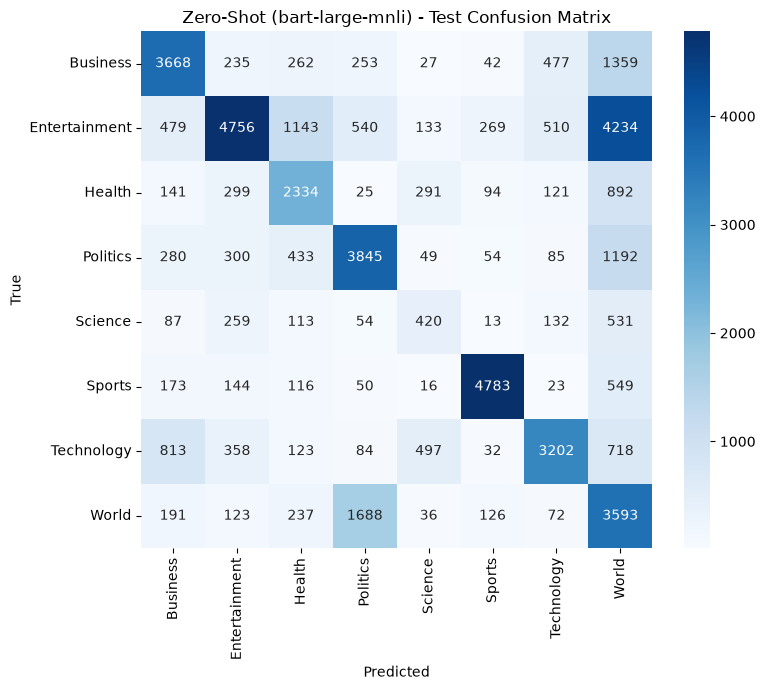

In [ ]:
import matplotlib.pyplot as plt  
import seaborn as sns  

RESULTS_DIR = Path("../../../results/zeroshot")  
RESULTS_DIR.mkdir(exist_ok=True, parents=True)  

plt.figure(figsize=(8, 7))  
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Zero-Shot (bart-large-mnli) - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "ZeroShot_a_confusion_matrix.png", dpi=150)
plt.show()

In [ ]:
metrics = {
    "model_family": "zeroshot",  
    "model_name": MODEL_CHECKPOINT,
    "run_timestamp": pd.Timestamp.utcnow().isoformat(),  
    "label_order": LABEL_ORDER,  
    "config": {
        "model_checkpoint": MODEL_CHECKPOINT,
        "hypothesis_template": HYPOTHESIS_TEMPLATE,
        "candidate_labels": CANDIDATE_LABELS,
        "batch_size": BATCH_SIZE,
        "full_test_size": len(test_df),  
        "sampling_strategy": sampling_strategy, 
    },
    "train": {
        "n_train": 0, 
        "n_val": 0, 
        "train_time_sec": 0.0,  
        "epochs_trained": None,
        "history": {},
    },
    "test": {
        "n_test": len(eval_df), 
        "accuracy": float(test_accuracy),
        "macro_precision": float(report_dict["macro avg"]["precision"]),
        "macro_recall": float(report_dict["macro avg"]["recall"]),
        "macro_f1": float(report_dict["macro avg"]["f1-score"]),
        "weighted_f1": float(report_dict["weighted avg"]["f1-score"]),
        "per_class": {
            cls: {
                "precision": float(report_dict[cls]["precision"]),
                "recall": float(report_dict[cls]["recall"]),
                "f1": float(report_dict[cls]["f1-score"]),
                "support": int(report_dict[cls]["support"]),
            }
            for cls in LABEL_ORDER
        },
        "confusion_matrix": cm.tolist(),
        "inference_time_sec_total": inf_time_sec,
        "inference_time_ms_per_sample": inf_time_sec / len(eval_df) * 1000,
    },
    "environment": {
        "framework": "pytorch+transformers",
        "framework_version": torch.__version__,
        "device": "GPU" if torch.cuda.is_available() else "CPU",
        "seed": SEED,
    },
}

with open(RESULTS_DIR / "ZeroShot_a_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)  

print("Saved:", RESULTS_DIR / "ZeroShot_a_metrics.json")

Saved: ..\..\..\results\zeroshot\ZeroShot_a_metrics.json


C:\Users\oofuc\AppData\Local\Temp\ipykernel_25824\2931916445.py:4: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  "run_timestamp": pd.Timestamp.utcnow().isoformat(),  # when this run completed
